# 01 — Baseline : CNN entraîné de zéro

Ce notebook établit le **point de référence** du parcours image : un réseau convolutif simple, initialisé
aléatoirement, qui n'apprend qu'à partir des images Rakuten. Son score, bon ou mauvais, mesure ce que les
données permettent d'apprendre sans aucune connaissance préalable.

Le protocole est strictement identique à celui du notebook 02 (transfer learning) :

- même manifeste, même split groupé et mêmes poids d'échantillon (notebook 00) ;
- même résolution 224 × 224, même augmentation, même perte, mêmes callbacks ;
- même tête de classification (pooling global, dropout 0,30, softmax à 27 classes).

Seuls l'architecture du corps convolutif et son initialisation changent. L'écart mesuré dans le
notebook 03 sera donc attribuable au transfert de connaissances d'ImageNet.


In [1]:
from pathlib import Path
import json
import os
import random

import certifi
import numpy as np
import pandas as pd

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Python installé depuis python.org sur macOS ne référence pas toujours le trousseau
# système. On fournit à urllib/Keras un bundle CA explicite sans désactiver SSL.
os.environ["SSL_CERT_FILE"] = certifi.where()
os.environ["REQUESTS_CA_BUNDLE"] = certifi.where()

def find_project_root() -> Path:
    """Permet d'exécuter le notebook depuis sa racine ou son propre dossier."""
    candidates = [Path.cwd(), *Path.cwd().parents]
    for candidate in candidates:
        if (candidate / "data" / "raw_x.csv").exists() and (candidate / "images").exists():
            return candidate
    raise FileNotFoundError("Racine du projet introuvable (data/raw_x.csv et images/ attendus).")

ROOT = find_project_root()
DATA_DIR = ROOT / "data"
IMAGE_DIR = ROOT / "images" / "image_train"
ARTIFACTS_DIR = ROOT / "artifacts" / "image_classification"
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("KERAS_HOME", str(ARTIFACTS_DIR / ".keras"))

print("Racine :", ROOT)
print("Artefacts :", ARTIFACTS_DIR)
print("Certificats SSL :", os.environ["SSL_CERT_FILE"])


Racine : /Users/wolfidy7/projects/sep25_alt2_iia_rakuten_2
Artefacts : /Users/wolfidy7/projects/sep25_alt2_iia_rakuten_2/artifacts/image_classification
Certificats SSL : /Users/wolfidy7/projects/sep25_alt2_iia_rakuten_2/.conda/rakuten-metal/lib/python3.10/site-packages/certifi/cacert.pem


In [2]:
import tensorflow as tf

tf.keras.utils.set_random_seed(SEED)

TARGET_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

with open(ARTIFACTS_DIR / "class_mapping.json", encoding="utf-8") as handle:
    class_mapping = json.load(handle)

index_to_code = [int(value) for value in class_mapping["index_to_code"]]
code_to_index = {code: index for index, code in enumerate(index_to_code)}
NUM_CLASSES = len(index_to_code)

manifest = pd.read_csv(ARTIFACTS_DIR / "image_manifest.csv")
manifest["class_index"] = manifest["prdtypecode"].map(code_to_index)
assert manifest["class_index"].notna().all()

def decode_resize(path, label, weight):
    image = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize_with_pad(image, *TARGET_SIZE, antialias=True)
    image = tf.cast(image, tf.float32)  # Pixels dans [0, 255] : chaque modèle gère sa mise à l'échelle.
    return image, tf.cast(label, tf.int32), tf.cast(weight, tf.float32)

def make_dataset(frame, training=False, transform=None, weighted=False):
    paths = frame["image_path"].astype(str).to_numpy()
    labels = frame["class_index"].astype("int32").to_numpy()
    weights = frame["sample_weight"].astype("float32").to_numpy()
    ds = tf.data.Dataset.from_tensor_slices((paths, labels, weights))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(decode_resize, num_parallel_calls=AUTOTUNE)
    if transform is not None:
        ds = ds.map(transform, num_parallel_calls=AUTOTUNE)
    if not weighted:
        ds = ds.map(lambda x, y, w: (x, y), num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

train_df = manifest.query("split == 'train'").copy()
val_df = manifest.query("split == 'validation'").copy()
print(f"Train={len(train_df):,} | Validation={len(val_df):,} | Classes={NUM_CLASSES}")


Train=65,900 | Validation=16,475 | Classes=27


In [3]:
import time

import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, classification_report, f1_score, top_k_accuracy_score
from tensorflow import keras
from tensorflow.keras import layers

def build_augmentation():
    """Augmentation identique pour tous les modèles : seule l'architecture change d'un run à l'autre."""
    return keras.Sequential(
        [
            layers.RandomRotation(0.03, fill_mode="reflect", seed=SEED),
            layers.RandomZoom(0.10, fill_mode="reflect", seed=SEED),
            layers.RandomContrast(0.10, seed=SEED),
        ],
        name="augmentation",
    )

def compile_model(model, learning_rate):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=[
            keras.metrics.SparseCategoricalAccuracy(name="accuracy"),
            keras.metrics.SparseTopKCategoricalAccuracy(k=3, name="top3_accuracy"),
        ],
    )

class EpochTimer(keras.callbacks.Callback):
    """Ajoute la durée de chaque époque au journal CSV."""

    def on_epoch_begin(self, epoch, logs=None):
        self._start = time.perf_counter()

    def on_epoch_end(self, epoch, logs=None):
        if logs is not None:
            logs["epoch_time_s"] = time.perf_counter() - self._start

def callbacks_for(run_dir, checkpoint_name, patience, append):
    run_dir.mkdir(parents=True, exist_ok=True)
    return [
        EpochTimer(),  # Doit précéder CSVLogger pour que la durée soit journalisée.
        keras.callbacks.ModelCheckpoint(
            run_dir / checkpoint_name, monitor="val_loss", save_best_only=True
        ),
        keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=patience, restore_best_weights=True
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.2, patience=2, min_lr=1e-7
        ),
        keras.callbacks.CSVLogger(run_dir / "training_log.csv", append=append),
    ]

def count_params(model):
    trainable = int(sum(np.prod(weight.shape) for weight in model.trainable_weights))
    return {"params_total": int(model.count_params()), "params_trainable": trainable}

def save_run_summary(run_dir, **values):
    """Fusionne les informations du run dans run_summary.json, relu par le notebook 03."""
    path = run_dir / "run_summary.json"
    summary = json.loads(path.read_text(encoding="utf-8")) if path.exists() else {}
    summary.update(values)
    path.write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8")
    return summary

def evaluate_on_validation(model, dataset, frame):
    probabilities = model.predict(dataset, verbose=1)
    y_true = frame["class_index"].to_numpy()
    y_pred = probabilities.argmax(axis=1)
    metrics = {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "top3_accuracy": float(top_k_accuracy_score(
            y_true, probabilities, k=3, labels=np.arange(NUM_CLASSES)
        )),
        "f1_weighted": float(f1_score(y_true, y_pred, average="weighted")),
        "f1_macro": float(f1_score(y_true, y_pred, average="macro")),
    }
    return metrics, y_true, y_pred

def plot_history(log_path, title, phase_boundary=None):
    log = pd.read_csv(log_path)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for ax, metric in zip(axes, ["loss", "accuracy"]):
        ax.plot(log["epoch"] + 1, log[metric], marker="o", label="train")
        ax.plot(log["epoch"] + 1, log[f"val_{metric}"], marker="o", label="validation")
        if phase_boundary is not None:
            ax.axvline(phase_boundary + 0.5, color="grey", linestyle="--", label="début du fine-tuning")
        ax.set_xlabel("Époque")
        ax.set_title(metric)
        ax.grid(alpha=0.3)
        ax.legend()
    fig.suptitle(title)
    plt.tight_layout(rect=(0, 0, 1, 1 - 0.6 / fig.get_figheight()))
    plt.show()


## Architecture

Le corps convolutif empile cinq blocs `Conv 3×3 → BatchNorm → ReLU` :

| Bloc | Filtres | Sortie | Rôle |
| --- | --- | --- | --- |
| 1 | 32 (stride 2) + max pooling | 56 × 56 | réduit vite la résolution pour limiter le coût |
| 2 | 64 + max pooling | 28 × 28 | motifs simples : bords, textures |
| 3 | 128 + max pooling | 14 × 14 | motifs composés |
| 4 | 256 | 14 × 14 | parties d'objets |
| 5 | 256 | 14 × 14 | dernière couche convolutive, utilisée par Grad-CAM |

- La couche `Rescaling(1/255)` est intégrée au modèle : le pipeline fournit des pixels dans `[0, 255]`,
  comme pour EfficientNet, et chaque modèle gère sa propre mise à l'échelle.
- La BatchNorm stabilise l'apprentissage depuis une initialisation aléatoire.
- Le corps est regroupé dans un sous-modèle nommé `features`, dont la sortie 14 × 14 × 256 sert de
  support aux cartes Grad-CAM du notebook 04.
- Le réseau compte environ 1 million de paramètres, tous entraînables, contre environ 4 millions
  (pré-entraînés) pour EfficientNetB0.


In [4]:
def conv_block(x, filters, name, strides=1, pool=True):
    x = layers.Conv2D(filters, 3, strides=strides, padding="same", use_bias=False, name=f"{name}_conv")(x)
    x = layers.BatchNormalization(name=f"{name}_bn")(x)
    x = layers.Activation("relu", name=f"{name}_relu")(x)
    if pool:
        x = layers.MaxPooling2D(name=f"{name}_pool")(x)
    return x

def build_cnn_scratch():
    image = keras.Input(shape=(*TARGET_SIZE, 3), name="pixels")
    x = layers.Rescaling(1.0 / 255, name="rescaling")(image)
    x = conv_block(x, 32, "block1", strides=2)
    x = conv_block(x, 64, "block2")
    x = conv_block(x, 128, "block3")
    x = conv_block(x, 256, "block4", pool=False)
    x = conv_block(x, 256, "block5", pool=False)
    features = keras.Model(image, x, name="features")

    inputs = keras.Input(shape=(*TARGET_SIZE, 3), name="image")
    x = build_augmentation()(inputs)
    x = features(x)
    x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
    x = layers.Dropout(0.30, seed=SEED)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="prdtypecode")(x)
    return keras.Model(inputs, outputs, name="cnn_scratch")


In [5]:
RUN_NAME = "cnn_scratch"
RUN_DIR = ARTIFACTS_DIR / RUN_NAME
train_ds = make_dataset(train_df, training=True, weighted=True)
val_ds = make_dataset(val_df, training=False, weighted=False)

model = build_cnn_scratch()
compile_model(model, learning_rate=1e-3)
model.get_layer("features").summary()
model.summary()
params = count_params(model)
print(params)


2026-10-14 15:32:11.652704: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M1 Pro
2026-10-14 15:32:11.652739: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-10-14 15:32:11.652742: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
2026-10-14 15:32:11.652765: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-10-14 15:32:11.652778: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Model: "features"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ pixels (InputLayer)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv (Conv2D)            │ (None, 112, 112, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_bn (BatchNormalization)  │ (None, 112, 112, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_relu (Activation)        │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv (Conv2D)            │ (None, 56, 56, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_bn (BatchNormalization)  │ (None, 56, 56, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_relu (Activation)        │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv (Conv2D)            │ (None, 28, 28, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_bn (BatchNormalization)  │ (None, 28, 28, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_relu (Activation)        │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv (Conv2D)            │ (None, 14, 14, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_bn (BatchNormalization)  │ (None, 14, 14, 256)    │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_relu (Activation)        │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv (Conv2D)            │ (None, 14, 14, 256)    │       589,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_bn (BatchNormalization)  │ (None, 14, 14, 256)    │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_relu (Activation)        │ (None, 14, 14, 256)    │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 980,704 (3.74 MB)

 Trainable params: 979,232 (3.74 MB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ features (Functional)           │ (None, 14, 14, 256)    │       980,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ prdtypecode (Dense)             │ (None, 27)             │         6,939 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 987,643 (3.77 MB)

 Trainable params: 986,171 (3.76 MB)

 Non-trainable params: 1,472 (5.75 KB)

{'params_total': 987643, 'params_trainable': 986171}


## Entraînement

- Adam avec un taux d'apprentissage de 1e-3, classique pour un réseau initialisé aléatoirement.
- Jusqu'à 30 époques : partant de zéro, le réseau converge plus lentement qu'une tête posée sur des
  représentations déjà apprises. L'arrêt anticipé (patience 5) coupe l'entraînement dès que la perte de
  validation ne progresse plus.
- Le meilleur modèle selon `val_loss` est sauvegardé dans `cnn_scratch/best_model.keras`.


In [6]:
EPOCHS = 30
start = time.perf_counter()
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks_for(RUN_DIR, "best_model.keras", patience=5, append=False),
)
train_time_min = (time.perf_counter() - start) / 60
model.save(RUN_DIR / "final_model.keras")
print(f"Durée d'entraînement : {train_time_min:.1f} min")


Epoch 1/30


2026-10-14 15:32:12.717829: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.



   1/2060 ━━━━━━━━━━━━━━━━━━━━ 1:38:44 3s/step - accuracy: 0.0000e+00 - loss: 3.6065 - top3_accuracy: 0.1250


   2/2060 ━━━━━━━━━━━━━━━━━━━━ 4:26 130ms/step - accuracy: 0.0078 - loss: 3.5875 - top3_accuracy: 0.1250    


   3/2060 ━━━━━━━━━━━━━━━━━━━━ 4:13 123ms/step - accuracy: 0.0295 - loss: 3.5464 - top3_accuracy: 0.1424

...


2058/2060 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step - accuracy: 0.5655 - loss: 1.4728 - top3_accuracy: 0.7744


2059/2060 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step - accuracy: 0.5655 - loss: 1.4728 - top3_accuracy: 0.7744


2060/2060 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step - accuracy: 0.5655 - loss: 1.4728 - top3_accuracy: 0.7744


2060/2060 ━━━━━━━━━━━━━━━━━━━━ 228s 110ms/step - accuracy: 0.5654 - loss: 1.4723 - top3_accuracy: 0.7747 - val_accuracy: 0.5415 - val_loss: 1.5702 - val_top3_accuracy: 0.7449 - epoch_time_s: 227.6942 - learning_rate: 1.0000e-07


Durée d'entraînement : 115.4 min


## Courbes d'apprentissage


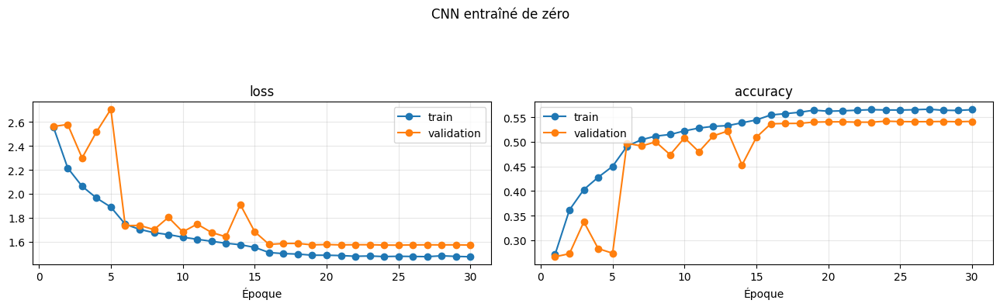

In [7]:
plot_history(RUN_DIR / "training_log.csv", "CNN entraîné de zéro")


Ces courbes montrent un modèle qui apprend, mais qui plafonne vite et dont la validation est instable au début.

# 1. Phase instable (époques 1 à 5)

La loss de validation oscille fortement (2,3, puis 2,7 à l'époque 5), alors que la loss d'entraînement baisse régulièrement.
L'accuracy de validation reste autour de 0,27 à 0,34, alors que celle d'entraînement monte de 0,27 à 0,45.
Ce décalage est un signal d'alerte. Les causes courantes sont un learning rate trop élevé au début, une normalisation par batch (BatchNorm) dont les statistiques ne sont pas stables en mode évaluation, ou un problème dans la boucle de validation.

# 2. Saut brutal à l'époque 6

Entre les époques 5 et 6, la validation passe de 0,27 à 0,49 d'accuracy et la loss chute de 2,7 à 1,74. Un changement aussi net dans les deux métriques suggère une modification de configuration, par exemple un scheduler de learning rate, un callback ou un changement de paramètres.
À partir de là, les deux courbes suivent une trajectoire cohérente.

# 3. Plateau et écart entre entraînement et validation (époques 16 à 30)

Train : loss ≈ 1,48, accuracy ≈ 0,565.
Validation : loss ≈ 1,57, accuracy ≈ 0,54.
L'écart est faible (environ 2,5 points d'accuracy). Il n'y a donc pas de surapprentissage marqué. Le modèle manque plutôt de capacité ou de données pour mieux généraliser.
Après l'époque 20 environ, plus rien ne s'améliore. Entraîner au-delà ne sert à rien. Un early stopping ferait gagner du temps sans perte de performance.

# 4. Ce que cela implique

Un CNN entraîné de zéro atteint ici environ 54 % d'accuracy de validation. C'est une base de référence correcte pour un problème à de nombreuses classes, mais limitée.
Le notebook 02 (transfer learning avec EfficientNet) devrait faire nettement mieux. C'est la comparaison à faire.
Si f1_macro est nettement inférieur à f1_weighted, cela confirmerait que les classes rares sont mal apprises, ce qui ne se voit pas dans ces courbes d'accuracy globale.

## Évaluation rapide sur la validation

On recharge les poids du meilleur checkpoint (`best_model.keras`) avant d'évaluer. Le notebook 03
réalise la comparaison complète avec les modèles transférés.


In [8]:
model.load_weights(RUN_DIR / "best_model.keras")
metrics, y_true, y_pred = evaluate_on_validation(model, val_ds, val_df)
display(pd.Series(metrics).to_frame("validation").style.format("{:.4f}"))
print(classification_report(y_true, y_pred, target_names=[str(code) for code in index_to_code]))

save_run_summary(
    RUN_DIR,
    label="CNN entraîné de zéro",
    epochs_run=len(history.history["loss"]),
    train_time_min=round(train_time_min, 1),
    **params,
    validation=metrics,
)



  1/515 ━━━━━━━━━━━━━━━━━━━━ 3:16 382ms/step


  4/515 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step  


  7/515 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step


 10/515 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step


 13/515 ━━━━━━━━━━━━━━━━━━━━ 9s 20ms/step 

...


515/515 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step


515/515 ━━━━━━━━━━━━━━━━━━━━ 13s 24ms/step


,validation
accuracy,0.5411
top3_accuracy,0.7451
f1_weighted,0.5196
f1_macro,0.4499


              precision    recall  f1-score   support

          10       0.52      0.64      0.57       591
          40       0.62      0.54      0.58       476
          50       0.42      0.14      0.21       320
          60       0.59      0.43      0.49       164
        1140       0.48      0.48      0.48       510
        1160       0.87      0.85      0.86       768
        1180       0.64      0.05      0.09       148
        1280       0.35      0.35      0.35       897
        1281       0.30      0.14      0.19       396
        1300       0.54      0.63      0.58       940
        1301       0.46      0.11      0.18       150
        1302       0.28      0.15      0.19       488
        1320       0.36      0.27      0.31       636
        1560       0.45      0.56      0.50       996
        1920       0.68      0.75      0.71       853
        1940       0.49      0.44      0.46       156
        2060       0.34      0.53      0.41       980
        2220       0.47    

{'label': 'CNN entraîné de zéro',
 'epochs_run': 30,
 'train_time_min': 115.4,
 'params_total': 987643,
 'params_trainable': 986171,
 'validation': {'accuracy': 0.541122913505311,
  'top3_accuracy': 0.7450682852807283,
  'f1_weighted': 0.5195885343089691,
  'f1_macro': 0.4499460183843356}}